# P5 - Đánh giá và tổng hợp

In [1]:
from pathlib import Path
def _need(p, hint):
    assert Path(p).exists(), f"❌ THIẾU INPUT: {p}\n   → {hint}"

import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
from scipy import stats
_need("common/config.yaml", "clone repo")
_need("common/segment_labels.parquet", "clone repo (P1 đã tạo)")
_need("data/processed/data_long.parquet", "chạy P1.ipynb hoặc tải data_long P1 gửi vào data/processed/")
CFG = yaml.safe_load(open("common/config.yaml", encoding="utf-8"))
Q = CFG["quantiles"]; H = CFG["horizon"]; SP = CFG["split"]
seg = pd.read_parquet("common/segment_labels.parquet")
windows = pd.read_csv("common/rolling_windows.csv")
long = pd.read_parquet("data/processed/data_long.parquet")
FCDIR = Path("data/outputs/forecasts")
forecasts = {p.stem: pd.read_parquet(p) for p in sorted(FCDIR.glob("*.parquet"))}
assert forecasts, "❌ Chưa có forecast nào trong data/outputs/forecasts/ — chờ P3/P4 chạy + push rồi git pull."
print("✅ Input sẵn sàng — forecast từ:", list(forecasts.keys()))

# ===== HỢP ĐỒNG LƯỚI (grid contract) - chặn so sánh lẫn quy mô =====
# Lưới chuẩn lấy từ common/: mọi forecast phải phủ ĐÚNG tập series × cửa sổ × quantile × H.
EXP_SERIES = set(long["series_id"].unique())
EXP_DINT = set()
for _, w in windows.iterrows():
    EXP_DINT |= set(range(int(w["test_start"]), int(w["test_end"]) + 1))
EXP_ROWS = len(windows) * len(EXP_SERIES) * H * len(Q)

def _grid_issues(df):
    iss = []
    if set(df["series_id"].unique()) != EXP_SERIES:
        iss.append(f"{df['series_id'].nunique()} series (cần {len(EXP_SERIES)})")
    if set(df["d_int"].unique()) != EXP_DINT:
        iss.append(f"{df['d_int'].nunique()} ngày test (cần {len(EXP_DINT)})")
    if sorted(df["quantile_level"].unique()) != sorted(Q):
        iss.append("sai quantile")
    return iss

_rows, forecasts_ok = [], {}
for name, df in forecasts.items():
    iss = _grid_issues(df)
    _rows.append({"model": name, "rows": len(df), "series": df["series_id"].nunique(),
                  "cửa sổ": int(df["d_int"].nunique() / H) if df["d_int"].nunique() % H == 0 else -1,
                  "trạng thái": "đúng lưới" if not iss else "LỆCH: " + "; ".join(iss)})
    if not iss:
        forecasts_ok[name] = df

coverage = pd.DataFrame(_rows)
print(coverage.to_string(index=False))
print(f"\nLưới chuẩn: {len(EXP_SERIES):,} series × {len(windows)} cửa sổ × {len(Q)} q × {H} ngày = {EXP_ROWS:,} dòng/model")
print(f"→ Dùng để đánh giá (forecasts_ok): {list(forecasts_ok.keys())}")
if len(forecasts_ok) < len(forecasts):
    print("⚠️  Có forecast LỆCH LƯỚI đã bị loại — chờ P3 chạy lại full-scale (lgbm + cổ điển).")
# LƯU Ý: phần đánh giá bên dưới hãy dùng `forecasts_ok` (không dùng `forecasts`) để tránh lẫn quy mô.

✅ Input sẵn sàng — forecast từ: ['chronos_bolt', 'croston', 'lgbm', 'moirai_2', 'naive', 'sba', 'snaive', 'tsb', 'ttm']


       model    rows  series  cửa sổ trạng thái
chronos_bolt 2626344    3474       3  đúng lưới
     croston 2626344    3474       3  đúng lưới
        lgbm 2626344    3474       3  đúng lưới
    moirai_2 2626344    3474       3  đúng lưới
       naive 2626344    3474       3  đúng lưới
         sba 2626344    3474       3  đúng lưới
      snaive 2626344    3474       3  đúng lưới
         tsb 2626344    3474       3  đúng lưới
         ttm 2626344    3474       3  đúng lưới

Lưới chuẩn: 3,474 series × 3 cửa sổ × 9 q × 28 ngày = 2,626,344 dòng/model
→ Dùng để đánh giá (forecasts_ok): ['chronos_bolt', 'croston', 'lgbm', 'moirai_2', 'naive', 'sba', 'snaive', 'tsb', 'ttm']


## Phần code chính

**Giao thức chốt trước khi xem kết quả (pre-registration):**

| Bước | Nội dung | Cài đặt |
|---|---|---|
| 6 | Hiệu chuẩn chung | Split-conformal một phía cho từng mức quantile (CQR), residual chuẩn hóa theo scale MAE-naive của chuỗi, Mondrian theo nhóm demand. Tập hiệu chuẩn của cửa sổ W là forecast validation RAW mà P3/P4 nộp (actual đều <= gốc test, không rò rỉ). Cùng một thủ tục cho mọi model. |
| 7 | Metric | RMSSE (điểm, chính), MASE (phụ), WSPL (xác suất, chính; trọng số doanh thu 28 ngày trước gốc), SPL (phụ), coverage 50/67/95/99 (chính), cùng độ rộng dải 95 và bias để phân tích lỗi. Báo cả raw và calibrated, theo balanced và frequency-weighted. |
| 8 | Kiểm định và win rule | Mỗi (nhóm, metric, bản): Diebold-Mariano panel (SE cluster theo chuỗi, Holm) và MCB tham chiếu. Thắng rõ khi model tốt nhất hơn mọi model khác ở cả 3 cửa sổ và qua DM (p Holm < 0.05); ngược lại là tương đương, khi đó chọn model rẻ nhất. |

**Lưu ý về gốc dự báo:** cổ điển dự báo test từ gốc test_start-1 (h = 1-28); LightGBM train <= train_end nhưng feature lag >= 28 dùng actual tới val_end; ba FM lấy context <= train_end và dự báo 56 ngày (val = h 1-28, test = h 29-56). Nghĩa là FM dự báo test xa hơn và residual hiệu chuẩn dễ hơn test, nên dải FM sau hiệu chuẩn có thể vẫn hơi hẹp; mọi kết luận về FM cần kèm lưu ý này.

In [2]:
# ---------- 6.0 Tham số đánh giá (chốt trước khi xem kết quả) ----------
from scipy.stats import rankdata, studentized_range, norm

Q = [round(float(q), 3) for q in Q]
QI = {q: i for i, q in enumerate(Q)}
SEG_ORDER = ["smooth", "erratic", "intermittent", "lumpy"]
COV_PAIRS = [(0.25, 0.75, 50), (0.165, 0.835, 67), (0.025, 0.975, 95), (0.005, 0.995, 99)]
METRICS = {"RMSSE": "điểm (chính)", "MASE": "điểm (phụ)", "WSPL": "xác suất (chính)", "SPL": "xác suất (phụ)"}
ALPHA = 0.05          # mức ý nghĩa DM / MCB
MIN_WINDOWS = 3       # win rule: chênh phải sống qua >= 3 cửa sổ rolling-origin
MIN_COVERAGE = 0.99   # model phải có forecast đủ cho >= 99% (chuỗi × cửa sổ) mới vào so sánh chính
PRIMARY = ("calibrated", "WSPL")   # tiêu chí của decision_table (bảng 1 dòng / nhóm cho P2)
# chi phí vận hành tương đối (chỉ dùng để phân định khi "tương đương"; thấp = rẻ)
COST_RANK = {"naive": 0, "snaive": 0, "croston": 1, "sba": 1, "tsb": 1,
             "lgbm": 2, "ttm": 3, "chronos_bolt": 4, "moirai_2": 5}

ids = pd.Index(sorted(pd.read_csv("common/sample_ids.csv")["series_id"]))
SEG = seg.set_index("series_id")["segment"].reindex(ids).to_numpy()
POP_SHARE = seg["segment"].value_counts(normalize=True).reindex(SEG_ORDER)   # tần suất thật (30.490 chuỗi)
windows = windows.sort_values("test_start", ascending=False).reset_index(drop=True)
WIN = {r.window: dict(origin=int(r.test_start) - 1, test=int(r.test_start), cal=int(r.train_end) + 1)
       for r in windows.itertuples()}
print("Mẫu:", len(ids), "chuỗi |", pd.Series(SEG).value_counts().reindex(SEG_ORDER).to_dict())
print("Cửa sổ:", {w: f"test d{v['test']}-{v['test']+H-1}, hiệu chuẩn (val) d{v['cal']}-{v['cal']+H-1}" for w, v in WIN.items()})
print("Tần suất thật:", POP_SHARE.round(3).to_dict())

Mẫu: 3474 chuỗi | {'smooth': 980, 'erratic': 494, 'intermittent': 1000, 'lumpy': 1000}
Cửa sổ: {'W1': 'test d1914-1941, hiệu chuẩn (val) d1886-1913', 'W2': 'test d1886-1913, hiệu chuẩn (val) d1858-1885', 'W3': 'test d1858-1885, hiệu chuẩn (val) d1830-1857'}
Tần suất thật: {'smooth': 0.032, 'erratic': 0.016, 'intermittent': 0.757, 'lumpy': 0.194}


In [3]:
# ---------- 6.1 Ma trận actual / giá + scale & trọng số tại từng gốc (chỉ dùng dữ liệu <= gốc) ----------
D_MAX = int(SP["max_actual_day"])
lg = long[long.series_id.isin(ids)]
_mat = lambda col: (lg.pivot(index="series_id", columns="d_int", values=col)
                      .reindex(index=ids, columns=range(1, D_MAX + 1)).to_numpy(np.float64))
Y, PRICE = _mat("sales"), _mat("sell_price")          # cột j <-> d_(j+1)
assert not np.isnan(Y).any(), "data_long thiếu actual cho một số (chuỗi, ngày) trong mẫu"
del lg

def scales_at(origin):
    """Scale kiểu M5 trên insample d_1..d_origin, tính từ lần bán đầu tiên: s1 = MAE naive-1, s2 = MSE naive-1."""
    y = Y[:, :origin]
    nz = y > 0
    first = np.where(nz.any(1), nz.argmax(1), origin)
    d = np.diff(y, axis=1)
    valid = np.arange(origin - 1)[None, :] >= first[:, None]
    n = np.maximum(valid.sum(1), 1)
    s1 = (np.abs(d) * valid).sum(1) / n
    s2 = (d ** 2 * valid).sum(1) / n
    s1[s1 <= 0] = np.nan; s2[s2 <= 0] = np.nan
    return s1, s2

def dollar_weight(origin):
    """Trọng số WSPL = doanh thu $ của 28 ngày cuối trước gốc (kiểu M5 Uncertainty)."""
    sl = slice(origin - H, origin)
    return np.nansum(Y[:, sl] * np.nan_to_num(PRICE[:, sl]), axis=1)

SCALE = {w: scales_at(v["origin"]) for w, v in WIN.items()}
WEIGHT = {w: dollar_weight(v["origin"]) for w, v in WIN.items()}
for w in WIN:
    print(w, "| chuỗi không có scale (chưa từng bán/không đổi trước gốc):", int(np.isnan(SCALE[w][0]).sum()))

W1 | chuỗi không có scale (chưa từng bán/không đổi trước gốc): 0
W2 | chuỗi không có scale (chưa từng bán/không đổi trước gốc): 0
W3 | chuỗi không có scale (chưa từng bán/không đổi trước gốc): 0


In [4]:
# ---------- 6.2 Forecast RAW (test + val) -> tensor (chuỗi × 28 ngày × 9 quantile) theo cửa sổ ----------
VALDIR = FCDIR / "val"
val_forecasts = {p.stem: pd.read_parquet(p) for p in sorted(VALDIR.glob("*.parquet"))}

def to_block(df, start):
    """Mảng (n_series, H, 9) cho đoạn [start, start+H); NaN nếu thiếu."""
    df = df[(df.d_int >= start) & (df.d_int < start + H) & df.series_id.isin(ids)]
    a = np.full((len(ids), H, len(Q)), np.nan)
    if len(df):
        qi = df.quantile_level.round(3).map(QI).fillna(-1).astype(int).to_numpy()
        m = qi >= 0
        a[ids.get_indexer(df.series_id)[m], df.d_int.to_numpy()[m] - start, qi[m]] = df.value.to_numpy(np.float64)[m]
    return a

def tidy(a):
    """Ép về miền hợp lệ: không âm + sắp lại quantile (rearrangement) nếu bị crossing."""
    return np.sort(np.clip(a, 0, None), axis=2)

def _crossing(a):
    ok = ~np.isnan(a).any(2)
    return float((np.diff(a, axis=2) < -1e-9).any(2)[ok].mean()) if ok.any() else np.nan

FC, cross_rate, avail = {}, {}, []
for name, df in forecasts_ok.items():          # chỉ forecast ĐÚNG LƯỚI (hợp đồng ở cell đầu)
    vdf = val_forecasts.get(name)
    FC[name] = {"test": {}, "cal": {}}
    cr = []
    for w, v in WIN.items():
        t = to_block(df, v["test"])
        c = to_block(vdf[vdf.window == w], v["cal"]) if vdf is not None and "window" in vdf else None
        cr.append(_crossing(t))
        FC[name]["test"][w] = tidy(t)
        if c is not None:
            FC[name]["cal"][w] = tidy(c)
        for role, a in (("test", t), ("cal", c)):
            frac = 0.0 if a is None else float((~np.isnan(a).any((1, 2))).mean())
            avail.append(dict(model=name, window=w, role=role, frac_series=frac))
    cross_rate[name] = float(np.nanmean(cr))

avail = pd.DataFrame(avail)
avail_tab = avail.pivot_table(index="model", columns=["role", "window"], values="frac_series")
print("Tỷ lệ chuỗi mẫu có forecast đủ 28×9 (test = chấm điểm, cal = forecast validation để hiệu chuẩn):")
display(avail_tab.round(3))
print("Tỷ lệ (chuỗi,ngày) bị quantile crossing trước khi sắp lại:", {k: round(v, 4) for k, v in cross_rate.items()})

test_ok = avail[avail.role == "test"].groupby("model").frac_series.min()
MODELS = sorted(test_ok[test_ok >= MIN_COVERAGE].index)
EXCLUDED = sorted(set(forecasts) - set(MODELS))
print("✅ Model vào so sánh chính:", MODELS)
if EXCLUDED:
    print("⚠ Bị loại (lệch lưới / thiếu chuỗi hoặc cửa sổ):", EXCLUDED)
no_val = sorted(set(MODELS) - set(val_forecasts))
if no_val:
    print("⚠ Thiếu forecast validation (forecasts/val/) → không có bản calibrated:", no_val)

Tỷ lệ chuỗi mẫu có forecast đủ 28×9 (test = chấm điểm, cal = forecast validation để hiệu chuẩn):


role          cal           test          
window         W1   W2   W3   W1   W2   W3
model                                     
chronos_bolt  1.0  1.0  1.0  1.0  1.0  1.0
croston       1.0  1.0  1.0  1.0  1.0  1.0
lgbm          1.0  1.0  1.0  1.0  1.0  1.0
moirai_2      1.0  1.0  1.0  1.0  1.0  1.0
naive         1.0  1.0  1.0  1.0  1.0  1.0
sba           1.0  1.0  1.0  1.0  1.0  1.0
snaive        1.0  1.0  1.0  1.0  1.0  1.0
tsb           1.0  1.0  1.0  1.0  1.0  1.0
ttm           1.0  1.0  1.0  1.0  1.0  1.0

Tỷ lệ (chuỗi,ngày) bị quantile crossing trước khi sắp lại: {'chronos_bolt': 0.0, 'croston': 0.0, 'lgbm': 0.0, 'moirai_2': 0.0, 'naive': 0.0, 'sba': 0.0, 'snaive': 0.0, 'tsb': 0.0, 'ttm': 0.0}
✅ Model vào so sánh chính: ['chronos_bolt', 'croston', 'lgbm', 'moirai_2', 'naive', 'sba', 'snaive', 'tsb', 'ttm']


### Bước 6 - Hiệu chuẩn chung (split-conformal)

Với mỗi model, cửa sổ *W*, nhóm *g* và mức quantile τ: lấy residual chuẩn hoá trên tập hiệu chuẩn
$r = (y - \hat q_\tau)/s_i$, rồi dịch quantile test một lượng $\delta_{g,\tau}\cdot s_i$, với $\delta$ là thống kê thứ tự
$\lceil (n+1)\tau \rceil$ (τ ≥ 0.5) hoặc $\lfloor (n+1)\tau \rfloor$ (τ < 0.5) của $r$ - bảo đảm coverage biên hữu hạn mẫu (Romano et al., 2019).
Không cần biết model sinh quantile thế nào (native / kẹp đuôi / bọc NB) -> so sánh công bằng.
Scale $s_i$ lấy tại gốc test (chỉ dữ liệu ≤ gốc). Model/cửa sổ nào **thiếu** forecast validation -> không có bản calibrated (ghi rõ trong bảng).

In [5]:
# ---------- 6.3 Split-conformal: offset theo (nhóm × mức quantile) ----------
def conformal_offsets(cal, y, s):
    r = (y[:, :, None] - cal) / s[:, None, None]
    ok_series = np.isfinite(s) & ~np.isnan(cal).any((1, 2))
    off = {}
    for g in SEG_ORDER:
        R = np.sort(r[ok_series & (SEG == g)].reshape(-1, len(Q)), axis=0)
        n = len(R)
        if n == 0:
            off[g] = np.zeros(len(Q)); continue
        k = np.array([np.ceil((n + 1) * t) if t >= 0.5 else np.floor((n + 1) * t) for t in Q])
        k = np.clip(k, 1, n).astype(int) - 1
        off[g] = R[k, np.arange(len(Q))]
    return off

def apply_offsets(a, off, s):
    shift = np.stack([off[g] for g in SEG]) * np.nan_to_num(s)[:, None]   # (n, 9)
    return tidy(a + shift[:, None, :])

CAL, OFFSETS = {}, []
for name in MODELS:
    for w, v in WIN.items():
        cal = FC[name]["cal"].get(w)
        if cal is None or (~np.isnan(cal).any((1, 2))).mean() < MIN_COVERAGE:
            continue
        y_cal = Y[:, v["cal"] - 1: v["cal"] - 1 + H]
        off = conformal_offsets(cal, y_cal, SCALE[w][0])
        CAL[(name, w)] = apply_offsets(FC[name]["test"][w], off, SCALE[w][0])
        OFFSETS += [dict(model=name, window=w, segment=g, quantile_level=q, offset_scaled=float(off[g][j]))
                    for g in SEG_ORDER for j, q in enumerate(Q)]
calibration_offsets = pd.DataFrame(OFFSETS)
# một cửa sổ chỉ có bản calibrated khi MỌI model đều hiệu chuẩn được (để so trên cùng tập)
cal_windows = sorted(w for w in WIN if all((m, w) in CAL for m in MODELS))
print("Cửa sổ có bản calibrated (đủ mọi model):", cal_windows)
missing_cal = sorted({m for m in MODELS for w in WIN if (m, w) not in CAL})
if missing_cal:
    print("  model thiếu forecast validation ở ít nhất 1 cửa sổ:", missing_cal)
if len(cal_windows) < MIN_WINDOWS:
    print(f"⚠ bản calibrated chỉ có {len(cal_windows)} cửa sổ → theo win rule chưa thể 'thắng rõ'.")

Cửa sổ có bản calibrated (đủ mọi model): ['W1', 'W2', 'W3']


### Bước 7: Chấm metric theo chuỗi rồi tổng hợp

- Theo chuỗi: RMSSE/MASE dùng P50; SPL = trung bình pinball 9 mức / s1; coverage của 4 dải đối xứng; độ rộng dải 95 (chuẩn hóa); bias = (P50 - actual)/s1.
- Tập so sánh: trong mỗi (bản, cửa sổ) chỉ giữ chuỗi mà mọi model đều có forecast và có scale, để chấm trên cùng một tập.
- Tổng hợp nhóm: trung bình chuỗi (WSPL trung bình có trọng số doanh thu). `window = ALL` là trung bình các cửa sổ; `ALL (balanced)` trung bình 4 nhóm ngang nhau; `ALL (frequency-weighted)` theo tần suất thật của nhóm trên 30.490 chuỗi.

In [6]:
# ---------- 7.1 Chấm theo chuỗi ----------
TAU = np.array(Q)

def score(F, y, s1, s2):
    q50 = F[:, :, QI[0.5]]
    e = y - q50
    diff = y[:, :, None] - F
    out = dict(RMSSE=np.sqrt((e ** 2).mean(1) / s2),
               MASE=np.abs(e).mean(1) / s1,
               SPL=np.maximum(TAU * diff, (TAU - 1) * diff).mean(1).mean(1) / s1)
    for lo, hi, nom in COV_PAIRS:
        out[f"cov{nom}"] = ((y >= F[:, :, QI[lo]]) & (y <= F[:, :, QI[hi]])).mean(1)
    # miss một phía của dải 95: với dữ liệu đếm có sàn 0, nếu P2.5 = 0 thì không thể miss phía dưới
    out["miss_lo95"] = (y < F[:, :, QI[0.025]]).mean(1)
    out["miss_hi95"] = (y > F[:, :, QI[0.975]]).mean(1)
    out["width95"] = (F[:, :, QI[0.975]] - F[:, :, QI[0.025]]).mean(1) / s1
    out["bias"] = (q50 - y).mean(1) / s1
    out["over_rate"] = (q50 > y).mean(1)
    out["under_rate"] = (q50 < y).mean(1)
    return out

rows = []
for version in ("raw", "calibrated"):
    for w, v in WIN.items():
        get = (lambda m: FC[m]["test"].get(w)) if version == "raw" else (lambda m: CAL.get((m, w)))
        arrs = {m: get(m) for m in MODELS}
        if any(a is None for a in arrs.values()):
            continue
        s1, s2 = SCALE[w]
        ok = np.isfinite(s1) & np.isfinite(s2)
        for a in arrs.values():
            ok &= ~np.isnan(a).any((1, 2))
        y = Y[ok, v["test"] - 1: v["test"] - 1 + H]
        for m, a in arrs.items():
            sc = score(a[ok], y, s1[ok], s2[ok])
            rows.append(pd.DataFrame(dict(version=version, window=w, model=m, series_id=ids[ok],
                                          segment=SEG[ok], weight=WEIGHT[w][ok], **sc)))
per_series = pd.concat(rows, ignore_index=True)
print("per_series:", per_series.shape)
display(per_series.groupby(["version", "window"]).series_id.nunique().unstack().rename_axis(None))

per_series: (187596, 19)


window,W1,W2,W3
calibrated,3474,3474,3474
raw,3474,3474,3474


In [7]:
# ---------- 7.2 Tổng hợp model × nhóm (theo cửa sổ + ALL), balanced & frequency-weighted ----------
COV_COLS = [f"cov{n}" for _, _, n in COV_PAIRS]
MEAN_COLS = ["RMSSE", "MASE", "SPL", *COV_COLS, "miss_lo95", "miss_hi95", "width95", "bias", "over_rate", "under_rate"]

def _agg(g):
    out = g[MEAN_COLS].mean()
    out["WSPL"] = np.average(g.SPL, weights=g.weight) if g.weight.sum() > 0 else np.nan
    out["n_series"] = len(g)
    return out

by_win = (per_series.groupby(["version", "window", "model", "segment"]).apply(_agg, include_groups=False)
          .reset_index())
all_win = (by_win.groupby(["version", "model", "segment"])
           .agg(**{c: (c, "mean") for c in MEAN_COLS + ["WSPL"]}, n_series=("n_series", "max"),
                n_windows=("window", "nunique"))
           .reset_index().assign(window="ALL"))
by_win["n_windows"] = 1
seg_tab = pd.concat([all_win, by_win], ignore_index=True)

def _overall(g, label, wts):
    g = g.set_index("segment").reindex(SEG_ORDER)
    out = {c: float(np.average(g[c], weights=wts)) for c in MEAN_COLS + ["WSPL"]}
    out.update(segment=label, n_series=int(g.n_series.sum()), n_windows=int(g.n_windows.max()))
    return pd.Series(out)

ov = []
for label, wts in [("ALL (balanced)", np.ones(4) / 4), ("ALL (frequency-weighted)", POP_SHARE.to_numpy())]:
    ov.append(seg_tab.groupby(["version", "window", "model"]).apply(lambda g: _overall(g, label, wts),
                                                                 include_groups=False).reset_index())
metrics_table = pd.concat([seg_tab, *ov], ignore_index=True)
metrics_table["cov_gap"] = np.mean([np.abs(metrics_table[f"cov{n}"] - n / 100) for _, _, n in COV_PAIRS], axis=0)
COLS_OUT = ["version", "window", "model", "segment", "n_series", "n_windows", "RMSSE", "MASE", "SPL", "WSPL",
            *COV_COLS, "cov_gap", "miss_lo95", "miss_hi95", "width95", "bias", "over_rate", "under_rate"]
SEG_ALL = SEG_ORDER + ["ALL (balanced)", "ALL (frequency-weighted)"]
metrics_table = (metrics_table[COLS_OUT]
                 .assign(segment=lambda d: pd.Categorical(d.segment, SEG_ALL, ordered=True))
                 .sort_values(["version", "window", "segment", "model"]).reset_index(drop=True))
metrics_table["segment"] = metrics_table.segment.astype(str)

def show(version, col, window="ALL"):
    t = (metrics_table.query("version == @version and window == @window")
         .pivot(index="model", columns="segment", values=col)[SEG_ALL])
    print(f"=== {col} · {version} · window={window} ==="); display(t.round(3))

for col in ["RMSSE", "WSPL", "cov95"]:
    for version in ("raw", "calibrated"):
        show(version, col)

=== RMSSE · raw · window=ALL ===


segment,smooth,erratic,intermittent,lumpy,ALL (balanced),ALL (frequency-weighted)
model,,,,,,
chronos_bolt,0.768,0.717,0.818,0.765,0.767,0.804
croston,0.765,0.725,0.851,0.798,0.785,0.836
lgbm,0.746,0.695,0.803,0.725,0.742,0.785
moirai_2,0.760,0.692,0.816,0.749,0.754,0.799
naive,0.940,0.822,0.887,0.819,0.867,0.875
sba,0.775,0.733,0.856,0.803,0.791,0.841
snaive,0.900,0.815,0.893,0.825,0.858,0.879
tsb,0.767,0.714,0.846,0.792,0.780,0.831
ttm,0.803,0.760,0.860,0.815,0.810,0.848


=== RMSSE · calibrated · window=ALL ===


segment,smooth,erratic,intermittent,lumpy,ALL (balanced),ALL (frequency-weighted)
model,,,,,,
chronos_bolt,0.765,0.714,0.819,0.766,0.766,0.806
croston,0.765,0.712,0.851,0.798,0.781,0.836
lgbm,0.737,0.694,0.803,0.726,0.740,0.784
moirai_2,0.749,0.687,0.817,0.749,0.751,0.799
naive,0.940,0.822,0.887,0.819,0.867,0.875
sba,0.766,0.715,0.856,0.803,0.785,0.840
snaive,0.890,0.789,0.893,0.825,0.849,0.878
tsb,0.767,0.703,0.846,0.792,0.777,0.831
ttm,0.803,0.745,0.860,0.815,0.806,0.847


=== WSPL · raw · window=ALL ===


...

segment,smooth,erratic,intermittent,lumpy,ALL (balanced),ALL (frequency-weighted)
model,,,,,,
chronos_bolt,0.211,0.254,0.300,0.330,0.274,0.302
croston,0.211,0.301,0.316,0.356,0.296,0.320
lgbm,0.200,0.248,0.260,0.300,0.252,0.265
moirai_2,0.210,0.241,0.284,0.306,0.260,0.285
naive,0.294,0.368,0.398,0.431,0.373,0.401
sba,0.211,0.298,0.316,0.355,0.295,0.320
snaive,0.254,0.340,0.374,0.413,0.345,0.377
tsb,0.216,0.305,0.318,0.362,0.300,0.323
ttm,0.224,0.307,0.331,0.375,0.309,0.335


=== cov95 · raw · window=ALL ===


segment,smooth,erratic,intermittent,lumpy,ALL (balanced),ALL (frequency-weighted)
model,,,,,,
chronos_bolt,0.788,0.780,0.717,0.742,0.757,0.725
croston,0.976,0.980,0.987,0.986,0.982,0.986
lgbm,0.972,0.971,0.981,0.975,0.975,0.979
moirai_2,0.810,0.804,0.690,0.727,0.758,0.703
naive,0.890,0.884,0.835,0.833,0.861,0.837
sba,0.973,0.978,0.985,0.984,0.980,0.985
snaive,0.862,0.856,0.819,0.807,0.836,0.819
tsb,0.973,0.975,0.971,0.965,0.971,0.970
ttm,0.966,0.978,0.980,0.976,0.975,0.979


=== cov95 · calibrated · window=ALL ===


segment,smooth,erratic,intermittent,lumpy,ALL (balanced),ALL (frequency-weighted)
model,,,,,,
chronos_bolt,0.945,0.948,0.944,0.947,0.946,0.945
croston,0.977,0.975,0.987,0.986,0.981,0.986
lgbm,0.974,0.971,0.974,0.972,0.973,0.973
moirai_2,0.953,0.954,0.948,0.951,0.951,0.949
naive,0.963,0.969,0.974,0.973,0.970,0.973
sba,0.975,0.975,0.985,0.984,0.980,0.985
snaive,0.969,0.973,0.974,0.974,0.972,0.974
tsb,0.973,0.977,0.976,0.973,0.975,0.975
ttm,0.966,0.976,0.980,0.976,0.974,0.979


### Hiệu chuẩn: coverage danh nghĩa so với thực tế (raw và calibrated)

Mỗi ô là model × nhóm. Đường chéo là hiệu chuẩn hoàn hảo; dưới đường chéo là dải quá hẹp (tự tin thừa).

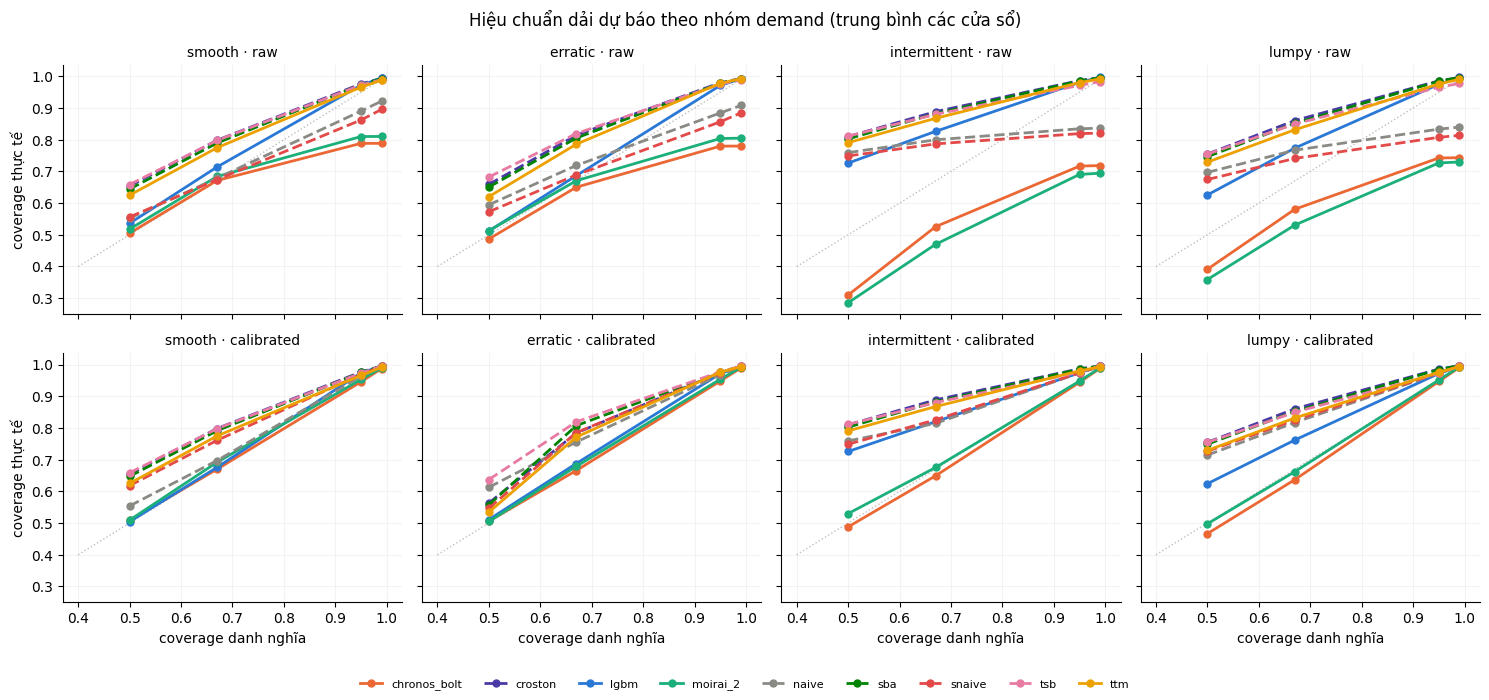

In [8]:
# ---------- 7.3 Reliability: coverage thực tế vs danh nghĩa ----------
NOM = [n / 100 for _, _, n in COV_PAIRS]
mt = metrics_table.query("window == 'ALL' and segment in @SEG_ORDER")
fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharex=True, sharey=True)
# màu cố định theo model (màu đi theo thực thể, không theo thứ hạng); nét đứt = họ cổ điển
COLOR = {"lgbm": "#2a78d6", "chronos_bolt": "#eb6834", "moirai_2": "#1baf7a", "ttm": "#eda100",
         "tsb": "#e87ba4", "sba": "#008300", "croston": "#4a3aa7", "snaive": "#e34948", "naive": "#8a8a85"}
STYLE = {m: "--" for m in ["naive", "snaive", "croston", "sba", "tsb"]}
for r, version in enumerate(("raw", "calibrated")):
    for c, g in enumerate(SEG_ORDER):
        ax = axes[r, c]
        ax.plot([0.4, 1], [0.4, 1], color="0.75", lw=1, ls=":")
        sub = mt.query("version == @version and segment == @g").set_index("model")
        for k, m in enumerate(MODELS):
            if m in sub.index:
                ax.plot(NOM, sub.loc[m, COV_COLS].to_numpy(float), marker="o", ms=5, lw=2,
                        ls=STYLE.get(m, "-"), color=COLOR.get(m, "#5f5e5a"), label=m)
        ax.set_title(f"{g} · {version}", fontsize=10)
        ax.grid(alpha=0.15); ax.spines[["top", "right"]].set_visible(False)
        if c == 0: ax.set_ylabel("coverage thực tế")
        if r == 1: ax.set_xlabel("coverage danh nghĩa")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=len(MODELS), fontsize=8, frameon=False)
fig.suptitle("Hiệu chuẩn dải dự báo theo nhóm demand (trung bình các cửa sổ)")
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

**Đọc coverage sau hiệu chuẩn.** Conformal hiệu chuẩn từng mức quantile một phía (P(y <= q'_τ) xấp xỉ τ). Với dữ liệu đếm có sàn 0, khi P2.5 = 0 thì không thể miss phía dưới, nên coverage dải 95% hội tụ về khoảng 0.975 chứ không phải 0.95 (xem `miss_lo95`, `miss_hi95`). Đây là tính chất của dữ liệu gián đoạn, không phải lỗi hiệu chuẩn: phía trên (phía quyết định tồn kho) vẫn đúng mức danh nghĩa.

### Bước 8 - Kiểm định DM + MCB và win rule

Với mỗi (bản × nhóm × metric), đơn vị quan sát = (chuỗi, cửa sổ):
- **best** = model có metric tổng hợp thấp nhất (WSPL: trọng số $ chuẩn hoá trong từng cửa sổ).
- **DM (panel)**: chênh loss $d = L_m - L_{best}$, trung bình (có trọng số với WSPL), sai số chuẩn **cluster theo chuỗi** (các cửa sổ của cùng chuỗi không độc lập); p hai phía, hiệu chỉnh **Holm** trên k−1 so sánh.
- **MCB**: xếp hạng các model trong từng đơn vị, hạng trung bình; model *m* khác *best* có ý nghĩa nếu hạng chênh > CD = $q_{\alpha,k,\infty}/\sqrt{2}\cdot\sqrt{k(k+1)/(6N)}$.
- **Cửa sổ**: best phải tốt hơn *m* trong **từng** cửa sổ, và số cửa sổ ≥ 3.
- *m* "thua rõ" ⇔ **tốt hơn ở mọi cửa sổ (≥3) VÀ DM có ý nghĩa** (win rule của nhóm: ≥3 cửa sổ + một kiểm định). DM được chọn làm kiểm định quyết định vì nó tôn trọng trọng số của metric (WSPL theo $); MCB dựa trên thứ hạng **không trọng số** và bị nhiễu bởi rất nhiều hoà hạng (chuỗi mà mọi model đều dự báo 0) -> chỉ báo cáo tham khảo. Best **"thắng rõ"** ⇔ mọi *m* đều thua rõ. Ngược lại **"tương đương"** với các model không thua rõ -> khuyến nghị model **rẻ nhất** trong nhóm tương đương.

*Hạn chế ghi nhận:* DM coi các chuỗi độc lập với nhau (cùng cửa hàng/ngày có thể tương quan) -> p-value có thể hơi lạc quan; vì vậy win rule đòi **thêm** tính ổn định qua cả 3 cửa sổ.

In [9]:
# ---------- 8.1 DM + MCB + win rule ----------
def test_group(df, metric):
    loss_col = "SPL" if metric == "WSPL" else metric
    L = df.pivot_table(index=["series_id", "window"], columns="model", values=loss_col).dropna()
    models = list(L.columns)
    if metric == "WSPL":
        w = df.drop_duplicates(["series_id", "window"]).set_index(["series_id", "window"]).weight.reindex(L.index)
        w = w / w.groupby(level="window").transform("sum")
    else:
        w = pd.Series(1.0, index=L.index)
    w = w.fillna(0)
    n_win = L.index.get_level_values("window").nunique()
    # giá trị tổng hợp (trung bình các cửa sổ) + theo từng cửa sổ
    per_win = L.mul(w, axis=0).groupby(level="window").sum().div(w.groupby(level="window").sum(), axis=0)
    agg = per_win.mean()
    best = agg.idxmin()
    # MCB
    k, N = len(models), len(L)
    ranks = pd.Series(rankdata(L.to_numpy(), axis=1).mean(0), index=models)
    cd = studentized_range.ppf(1 - ALPHA, k, np.inf) / np.sqrt(2) * np.sqrt(k * (k + 1) / (6 * N)) if k > 1 else np.nan
    # DM panel, cluster theo chuỗi
    sid = L.index.get_level_values("series_id")
    res = []
    for m in models:
        if m == best:
            continue
        d = (L[m] - L[best]).to_numpy()
        ww = w.to_numpy()
        est = np.sum(ww * d) / np.sum(ww)
        u = pd.Series(ww * (d - est)).groupby(sid).sum().to_numpy()
        se = np.sqrt(np.sum(u ** 2)) / np.sum(ww)
        z = est / se if se > 0 else (np.inf if est > 0 else 0.0)
        res.append(dict(model=m, value=agg[m], diff_pct=100 * (agg[m] - agg[best]) / agg[best],
                        dm_stat=z, p_dm=2 * norm.sf(abs(z)), mcb_rank_diff=ranks[m] - ranks[best],
                        better_all_windows=bool((per_win[best] < per_win[m]).all()) and n_win >= MIN_WINDOWS))
    res = pd.DataFrame(res).sort_values("value").reset_index(drop=True)
    # Holm
    order = np.argsort(res.p_dm.to_numpy())
    padj = np.empty(len(res)); running = 0.0
    for i, j in enumerate(order):
        running = max(running, min(1.0, (len(res) - i) * res.p_dm.iloc[j]))
        padj[j] = running
    res["p_dm_holm"] = padj
    res["mcb_sig"] = res.mcb_rank_diff > cd
    res["sig_worse"] = (res.p_dm_holm < ALPHA) & (res.dm_stat > 0) & res.better_all_windows   # MCB: tham khảo
    tied = [best] + res.loc[~res.sig_worse, "model"].tolist()
    verdict = "thắng rõ" if len(tied) == 1 else "tương đương"
    recommended = best if verdict == "thắng rõ" else min(tied, key=lambda m: (COST_RANK.get(m, 99), agg[m]))
    ru = res.iloc[0] if len(res) else None
    summary = dict(metric=metric, metric_role=METRICS[metric], n_series=L.index.get_level_values(0).nunique(),
                   n_windows=n_win, n_models=k, best_model=best, best_value=agg[best],
                   runner_up=None if ru is None else ru.model, runner_up_value=np.nan if ru is None else ru.value,
                   margin_pct=np.nan if ru is None else ru.diff_pct,
                   p_dm_holm_runner_up=np.nan if ru is None else ru.p_dm_holm,
                   mcb_cd=cd, mcb_rank_best=ranks[best],
                   mcb_rank_runner_up=np.nan if ru is None else ranks[ru.model],
                   best_all_windows_vs_runner_up=None if ru is None else ru.better_all_windows,
                   tied_models=", ".join(tied), verdict=verdict, recommended_model=recommended,
                   reason=("thắng rõ (≥3 cửa sổ + DM)" if verdict == "thắng rõ" else
                           ("chưa đủ 3 cửa sổ" if n_win < MIN_WINDOWS else "không qua đủ DM + mọi cửa sổ")
                           + (" → chọn model rẻ nhất trong nhóm tương đương" if recommended != best else "")))
    res.insert(0, "best_model", best)
    return summary, res

dec_rows, pair_rows = [], []
for version in ("raw", "calibrated"):
    for g in SEG_ORDER:
        df = per_series.query("version == @version and segment == @g")
        if df.empty or df.model.nunique() < 2:
            continue
        for metric in METRICS:
            s, p = test_group(df, metric)
            dec_rows.append(dict(version=version, segment=g, **s))
            pair_rows.append(p.assign(version=version, segment=g, metric=metric))
decision_full = pd.DataFrame(dec_rows)
significance_tests = pd.concat(pair_rows, ignore_index=True)
significance_tests = significance_tests[["version", "segment", "metric", "best_model", "model", "value", "diff_pct",
                                         "dm_stat", "p_dm", "p_dm_holm", "mcb_rank_diff", "mcb_sig",
                                         "better_all_windows", "sig_worse"]]
display(decision_full[["version", "segment", "metric", "n_windows", "best_model", "runner_up", "margin_pct",
                       "p_dm_holm_runner_up", "verdict", "tied_models", "recommended_model"]]
        .round(4))

,version,segment,metric,n_windows,best_model,runner_up,margin_pct,p_dm_holm_runner_up,verdict,tied_models,recommended_model
0,raw,smooth,RMSSE,3,lgbm,moirai_2,1.8909,0.0000,thắng rõ,lgbm,lgbm
1,raw,smooth,MASE,3,lgbm,croston,1.6834,0.0002,thắng rõ,lgbm,lgbm
2,raw,smooth,WSPL,3,lgbm,sba,4.7265,0.0000,thắng rõ,lgbm,lgbm
3,raw,smooth,SPL,3,lgbm,croston,2.8459,0.0000,thắng rõ,lgbm,lgbm
4,raw,erratic,RMSSE,3,moirai_2,lgbm,0.5093,0.3917,tương đương,"moirai_2, lgbm",lgbm
5,raw,erratic,MASE,3,moirai_2,lgbm,0.6874,0.3589,tương đương,"moirai_2, lgbm, tsb, croston, sba",tsb
6,raw,erratic,WSPL,3,lgbm,moirai_2,4.6003,0.2861,tương đương,"lgbm, moirai_2, sba, croston, tsb, ttm",sba
7,raw,erratic,SPL,3,lgbm,tsb,4.2980,0.0001,tương đương,"lgbm, tsb",tsb
8,raw,intermittent,RMSSE,3,lgbm,moirai_2,1.5849,0.0000,thắng rõ,lgbm,lgbm
9,raw,intermittent,MASE,3,lgbm,moirai_2,1.1487,0.3476,tương đương,"lgbm, moirai_2, chronos_bolt, tsb, croston, sb...",tsb


In [10]:
# ---------- 8.2 Bảng quyết định (1 dòng / nhóm) - tiêu chí chính: WSPL bản calibrated ----------
def _pick(version, metric):
    return decision_full.query("version == @version and metric == @metric").set_index("segment").reindex(SEG_ORDER)

pv, pm = PRIMARY
prim = _pick(pv, pm)
if prim.best_model.isna().all():          # chưa có bản calibrated -> tạm dùng raw, ghi rõ
    pv = "raw"; prim = _pick(pv, pm)
rmsse = _pick(pv, "RMSSE")
cov = metrics_table.query("version == @pv and window == 'ALL'").set_index(["segment", "model"]).cov95

decision_table = pd.DataFrame({
    "Nhóm demand": SEG_ORDER,
    # giữ tên cột cũ để notebook P2 (bước 9) đọc được; nội dung = model KHUYẾN NGHỊ theo tiêu chí bên dưới
    "Nên dùng (SPL)": prim.recommended_model.to_numpy(),
    "Độ tin cậy": prim.verdict.to_numpy(),
    "Chênh vs á quân (%)": prim.margin_pct.round(1).to_numpy(),
    "Tiêu chí": f"{pm} · {pv}",
    "Model tốt nhất": prim.best_model.to_numpy(),
    "Á quân": prim.runner_up.to_numpy(),
    "p DM (Holm) vs á quân": prim.p_dm_holm_runner_up.to_numpy(),
    "Nhóm tương đương": prim.tied_models.to_numpy(),
    "Số cửa sổ": prim.n_windows.to_numpy(),
    "Số chuỗi": prim.n_series.to_numpy(),
    "Coverage-95 của model khuyến nghị": [cov.get((g, m), np.nan) for g, m in zip(SEG_ORDER, prim.recommended_model)],
    "Khuyến nghị theo RMSSE": rmsse.recommended_model.to_numpy(),
    "Độ tin cậy (RMSSE)": rmsse.verdict.to_numpy(),
})
print("╔══════════ BẢNG QUYẾT ĐỊNH — nhu cầu nào → model nào ══════════╗")
display(decision_table.round(3))

╔══════════ BẢNG QUYẾT ĐỊNH — nhu cầu nào → model nào ══════════╗


,Nhóm demand,Nên dùng (SPL),Độ tin cậy,Chênh vs á quân (%),Tiêu chí,Model tốt nhất,Á quân,p DM (Holm) vs á quân,Nhóm tương đương,Số cửa sổ,Số chuỗi,Coverage-95 của model khuyến nghị,Khuyến nghị theo RMSSE,Độ tin cậy (RMSSE)
0,smooth,lgbm,thắng rõ,4.9,WSPL · calibrated,lgbm,moirai_2,0.007,lgbm,3,980,0.974,lgbm,thắng rõ
1,erratic,snaive,tương đương,3.1,WSPL · calibrated,moirai_2,lgbm,0.418,"moirai_2, lgbm, sba, croston, tsb, ttm, snaive",3,494,0.973,tsb,tương đương
2,intermittent,croston,tương đương,9.4,WSPL · calibrated,lgbm,moirai_2,0.163,"lgbm, moirai_2, chronos_bolt, croston, sba, ts...",3,1000,0.987,lgbm,thắng rõ
3,lumpy,lgbm,tương đương,2.2,WSPL · calibrated,lgbm,moirai_2,0.302,"lgbm, moirai_2",3,1000,0.972,lgbm,thắng rõ


## Cell cuối: lưu output (điền biến theo comment rồi chạy)

In [11]:
# ===== lưu output =====
# metrics_table (model×nhóm) và decision_table (bảng thắng theo nhóm)
Path("data/outputs").mkdir(parents=True, exist_ok=True)
metrics_table.to_parquet("data/outputs/metrics_by_model_segment.parquet", index=False)
decision_table.to_parquet("data/outputs/decision_table.parquet", index=False)
print("✅ Đã lưu metrics_by_model_segment + decision_table")

✅ Đã lưu metrics_by_model_segment + decision_table


## Biểu đồ tổng hợp kết quả

*Đọc từ `data/outputs/metrics_by_model_segment.parquet` đã lưu, chỉ minh họa, không đổi logic hay output.*

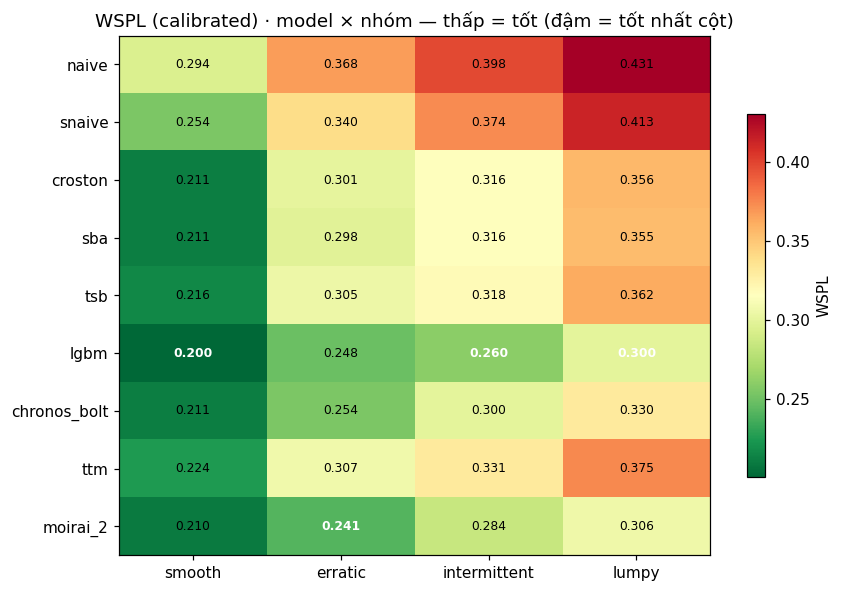

In [12]:
# Biểu đồ A - WSPL (calibrated) theo model × nhóm (thấp = tốt; đậm = tốt nhất cột)
import matplotlib.pyplot as plt
import pandas as pd, numpy as np
m = pd.read_parquet("data/outputs/metrics_by_model_segment.parquet")
order = ["naive","snaive","croston","sba","tsb","lgbm","chronos_bolt","ttm","moirai_2"]
segs = ["smooth","erratic","intermittent","lumpy"]
d = m[(m.version=="calibrated") & (m.window=="ALL") & (m.segment.isin(segs))]
piv = d.pivot(index="model", columns="segment", values="WSPL").reindex(order)[segs]
fig, ax = plt.subplots(figsize=(8, 5.5))
im = ax.imshow(piv.values, cmap="RdYlGn_r", aspect="auto")
ax.set_xticks(range(len(segs))); ax.set_xticklabels(segs)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
for i in range(len(order)):
    for j in range(len(segs)):
        v = piv.values[i, j]
        best = v == np.nanmin(piv[segs[j]].values)
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8,
                fontweight="bold" if best else "normal", color="white" if best else "black")
ax.set_title("WSPL (calibrated) · model × nhóm — thấp = tốt (đậm = tốt nhất cột)")
fig.colorbar(im, ax=ax, shrink=0.7, label="WSPL")
fig.tight_layout(); plt.show()

*WSPL (chất lượng dải, đã hiệu chuẩn): LightGBM tốt nhất ở smooth; các nhóm thưa nhiều model tương đương.*

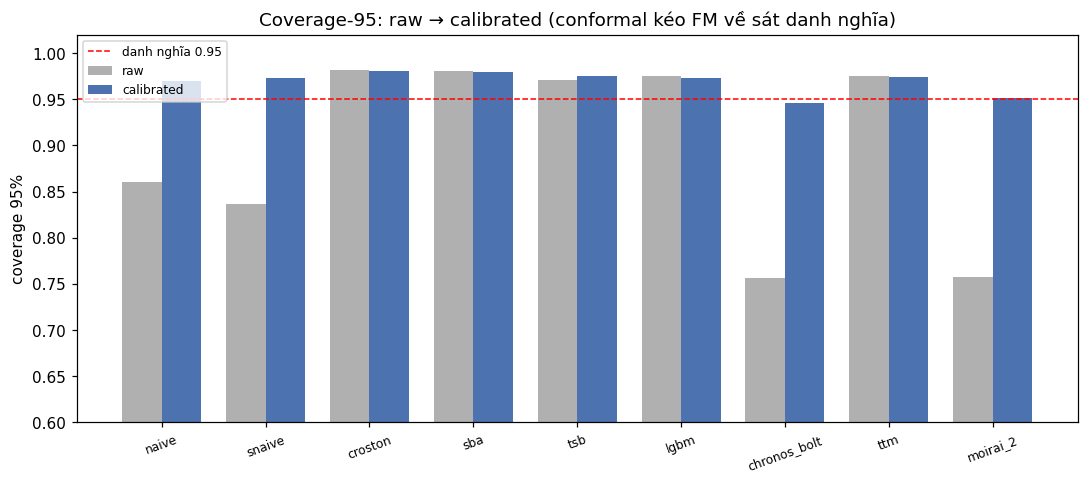

In [13]:
# Biểu đồ B - Coverage-95: raw -> calibrated theo model (nhóm ALL balanced)
import matplotlib.pyplot as plt
import pandas as pd, numpy as np
m = pd.read_parquet("data/outputs/metrics_by_model_segment.parquet")
order = ["naive","snaive","croston","sba","tsb","lgbm","chronos_bolt","ttm","moirai_2"]
d = m[(m.window=="ALL") & (m.segment=="ALL (balanced)")]
raw = d[d.version=="raw"].set_index("model")["cov95"].reindex(order)
cal = d[d.version=="calibrated"].set_index("model")["cov95"].reindex(order)
x = np.arange(len(order)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - w/2, raw.values, w, label="raw", color="#B0B0B0")
ax.bar(x + w/2, cal.values, w, label="calibrated", color="#4C72B0")
ax.axhline(0.95, ls="--", color="red", lw=1, label="danh nghĩa 0.95")
ax.set_xticks(x); ax.set_xticklabels(order, rotation=20, fontsize=8)
ax.set_ylim(0.6, 1.02); ax.set_ylabel("coverage 95%")
ax.set_title("Coverage-95: raw → calibrated (conformal kéo FM về sát danh nghĩa)")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

*Conformal kéo coverage-95 của Chronos/Moirai từ ~0.75 (kẹp đuôi) về ~0.95; nhóm bọc-NB vốn đã sát/hơi thừa.*

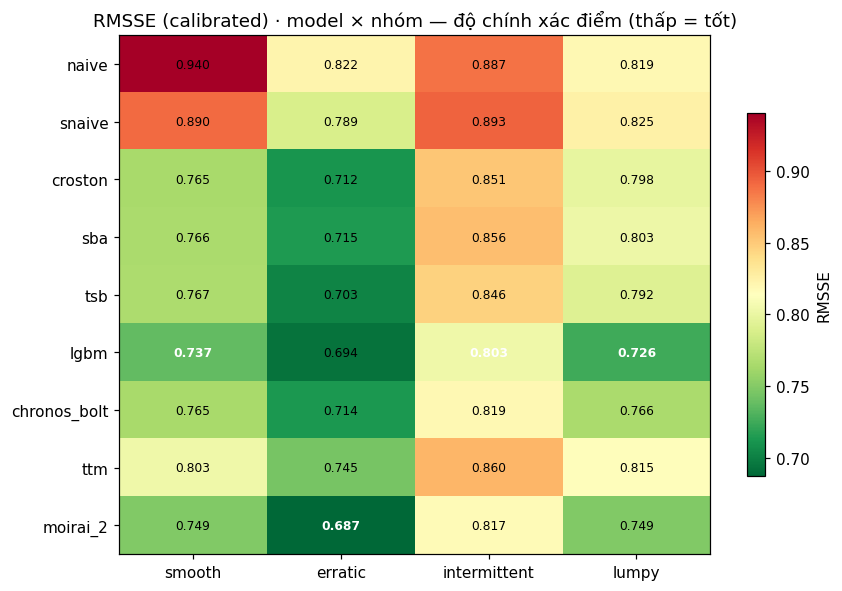

In [14]:
# Biểu đồ C - RMSSE (calibrated) theo model × nhóm (thấp = tốt)
import matplotlib.pyplot as plt
import pandas as pd, numpy as np
m = pd.read_parquet("data/outputs/metrics_by_model_segment.parquet")
order = ["naive","snaive","croston","sba","tsb","lgbm","chronos_bolt","ttm","moirai_2"]
segs = ["smooth","erratic","intermittent","lumpy"]
d = m[(m.version=="calibrated") & (m.window=="ALL") & (m.segment.isin(segs))]
piv = d.pivot(index="model", columns="segment", values="RMSSE").reindex(order)[segs]
fig, ax = plt.subplots(figsize=(8, 5.5))
im = ax.imshow(piv.values, cmap="RdYlGn_r", aspect="auto")
ax.set_xticks(range(len(segs))); ax.set_xticklabels(segs)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
for i in range(len(order)):
    for j in range(len(segs)):
        v = piv.values[i, j]
        best = v == np.nanmin(piv[segs[j]].values)
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8,
                fontweight="bold" if best else "normal", color="white" if best else "black")
ax.set_title("RMSSE (calibrated) · model × nhóm — độ chính xác điểm (thấp = tốt)")
fig.colorbar(im, ax=ax, shrink=0.7, label="RMSSE")
fig.tight_layout(); plt.show()

*RMSSE (độ chính xác điểm): LightGBM dẫn ở phần lớn nhóm; Naive kém nhất, đúng kỳ vọng.*